## A1. Deskripsi Dataset
Dataset yang digunakan dalam tugas Linear Regression ini adalah **California Housing Dataset**. Dataset ini berisi informasi karakteristik wilayah di California, Amerika Serikat, yang digunakan untuk memprediksi nilai median rumah.
Dataset berasal dari StatLib dan diturunkan dari data sensus Amerika Serikat tahun 1990. Setiap baris mewakili satu kelompok wilayah sensus (*census block group*), bukan satu rumah individual. Dataset diakses memakai fungsi `fetch_california_housing()` dari library scikit-learn.
Dataset ini memiliki 20.640 baris, delapan fitur input, dan satu variabel target, sehingga totalnya sembilan kolom. Variabel target yang dipakai adalah `MedHouseVal`, yaitu nilai median rumah di suatu wilayah yang dinyatakan dalam satuan ratusan ribu dolar AS.

Sumber: [Dokumentasi resmi scikit-learn — California Housing](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html

Sumber dataset asli: [StatLib — California Housing](https://lib.stat.cmu.edu/datasets/houses.zip)


### Penjelasan Fitur dan Variabel Target

Dataset California Housing memiliki delapan fitur input dan satu variabel target. Berikut penjelasan setiap kolom yang dipakai.

| Kolom | Arti |
|---|---|
| `MedInc` | Pendapatan median pada suatu kelompok wilayah sensus. |
| `HouseAge` | Usia median rumah pada wilayah tersebut. |
| `AveRooms` | Rata-rata jumlah ruangan per rumah tangga. |
| `AveBedrms` | Rata-rata jumlah kamar tidur per rumah tangga. |
| `Population` | Jumlah penduduk di wilayah tersebut. |
| `AveOccup` | Rata-rata jumlah penghuni per rumah tangga. |
| `Latitude` | Garis lintang wilayah. |
| `Longitude` | Garis bujur wilayah. |
| `MedHouseVal` | **Variabel target:** nilai median rumah pada wilayah tersebut. |

**Catatan:** Variabel target `MedHouseVal` dinyatakan dalam satuan ratusan ribu dolar AS. Sebagai contoh, nilai target 2,5 setara dengan sekitar US$250.000. Karena data direpresentasikan pada tingkat kelompok wilayah sensus, nilai tersebut bukan harga pasti sebuah rumah individual.

In [ ]:
from sklearn.datasets import fetch_california_housing

# memuat dataset California Housing
housing = fetch_california_housing(as_frame=True)

# membuat DataFrame yang berisi fitur dan target
df = housing.frame.copy()

# menentukan nama kolom target
target_column = "MedHouseVal"

# menampilkan informasi dataset
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("Jumlah fitur input:", len(housing.feature_names))
print("Variabel target:", target_column)

# menampilkan nama seluruh kolom
print("\nDaftar kolom:")
print(df.columns.tolist())

# menampilkan lima baris pertama
display(df.head())

Jumlah baris: 20640
Jumlah kolom: 9
Jumlah fitur input: 8
Variabel target: MedHouseVal

Daftar kolom:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Checklist A1

- [x] Deskripsi dataset dan asal sumber sudah ditulis.
- [x] Kode berhasil dijalankan dan jumlah baris serta kolom sudah tampil.
- [x] Delapan fitur input sudah dijelaskan.
- [x] Variabel target `MedHouseVal` beserta satuannya sudah dijelaskan.
- [x] Tautan sumber dataset sudah dicantumkan.

## A2. Eksplorasi dan Visualisasi Data

Eksplorasi data dilakukan untuk memahami karakteristik dataset California Housing sebelum membangun model Linear Regression. Analisis ini mencakup statistik deskriptif dan visualisasi untuk melihat distribusi variabel target, hubungan antarvariabel, serta hubungan fitur dengan target.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# menampilkan statistik deskriptif seluruh kolom
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


### Interpretasi Statistik Deskriptif

Statistik deskriptif dipakai untuk memahami nilai rata-rata, penyebaran, dan rentang nilai dari setiap fitur serta variabel target. Perbedaan rentang nilai antarkolom juga perlu dicek sebelum menentukan tahapan preprocessing pada tahap berikutnya.

### Visualisasi 1 — Distribusi Variabel Target

Histogram digunakan untuk melihat distribusi nilai `MedHouseVal`, mengetahui rentang nilai yang paling sering muncul, dan mengamati apakah distribusinya terkonsentrasi pada rentang tertentu.

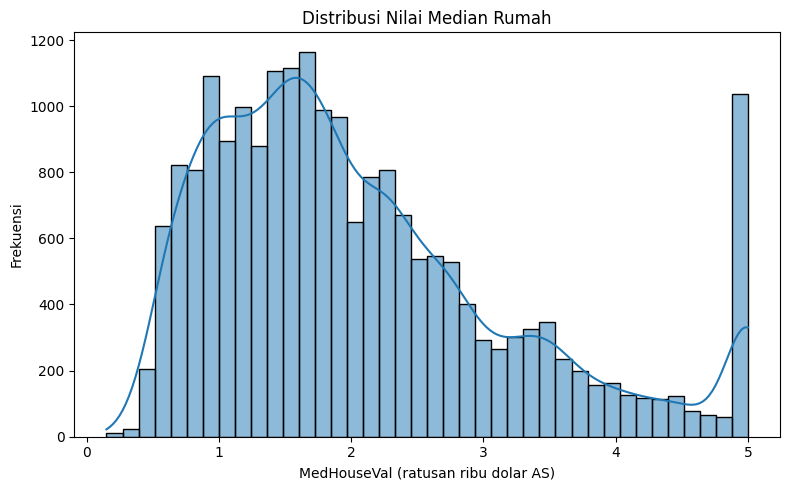

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x=target_column,
    bins=40,
    kde=True
)

plt.title("Distribusi Nilai Median Rumah")
plt.xlabel("MedHouseVal (ratusan ribu dolar AS)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

**Temuan:**

Histogram menunjukkan sebaran nilai median rumah dalam dataset California Housing. Sebagian besar nilai target terkonsentrasi pada rentang tertentu, sedangkan nilai yang lebih tinggi muncul dengan frekuensi lebih rendah. Terlihat juga penumpukan nilai di sekitar 5,0 karena nilai target dalam dataset ini memiliki batas atas.

Distribusi tersebut menunjukkan bahwa nilai target tidak tersebar secara merata. Batas atas target juga perlu diperhatikan ketika menafsirkan hasil prediksi model.

### Visualisasi 2 — Heatmap Korelasi

Heatmap korelasi dipakai untuk mengamati hubungan linear antarfitur dan antara setiap fitur dengan variabel target. Koefisien korelasi berkisar dari -1 hingga +1. Nilai positif menunjukkan hubungan searah, nilai negatif menunjukkan hubungan berlawanan arah, dan nilai yang mendekati 0 menunjukkan hubungan linear yang lemah.

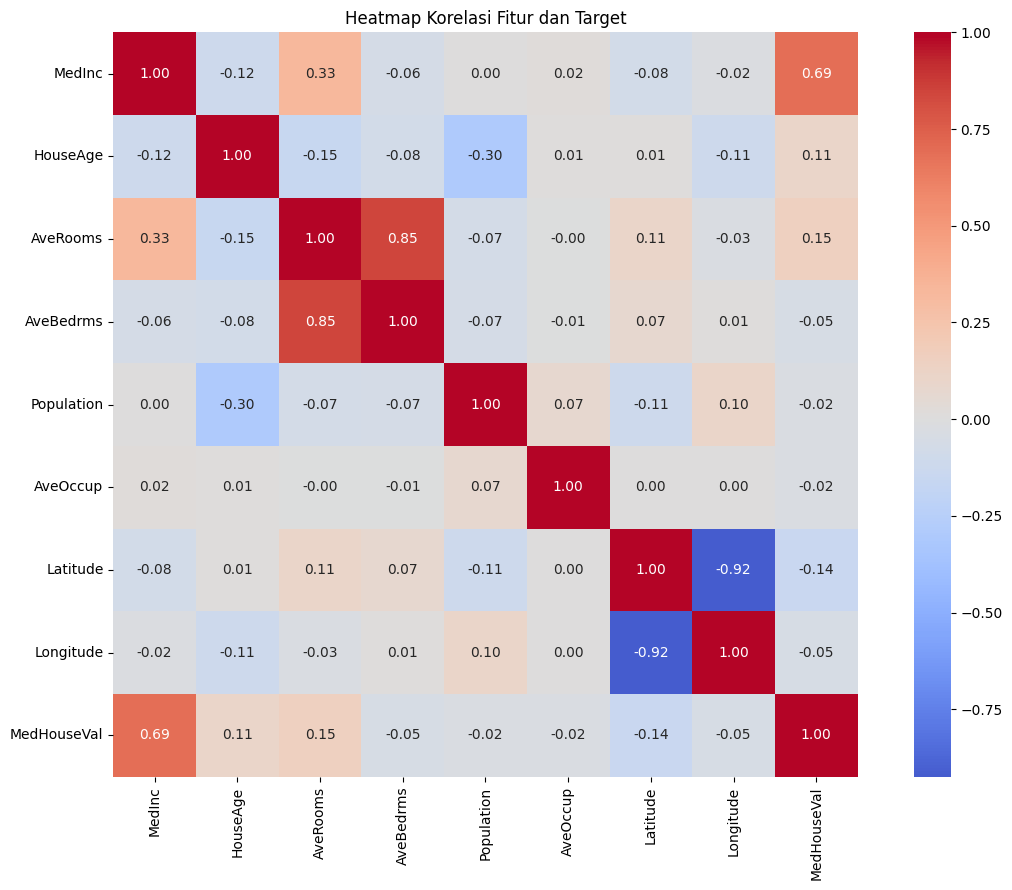

In [ ]:
# menghitung korelasi antarfitur dan target
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Heatmap Korelasi Fitur dan Target")
plt.tight_layout()
plt.show()

**Temuan:**

Heatmap menunjukkan bahwa kekuatan hubungan linear berbeda-beda pada setiap pasangan variabel. Hubungan `MedInc` dengan `MedHouseVal` tampak positif dan relatif lebih kuat dibandingkan hubungan target dengan sebagian besar fitur lainnya. Artinya, wilayah dengan pendapatan median lebih tinggi cenderung memiliki nilai median rumah yang lebih tinggi.

Heatmap juga membantu mengidentifikasi fitur yang saling berkorelasi. Namun, korelasi tidak membuktikan hubungan sebab-akibat.

### Visualisasi 3 — Hubungan Pendapatan Median dan Nilai Rumah

Scatter plot digunakan untuk melihat hubungan antara `MedInc` sebagai fitur input dan `MedHouseVal` sebagai variabel target. Setiap titik mewakili data satu kelompok wilayah sensus. Pola titik membantu menunjukkan arah hubungan dan variasi nilai target pada tingkat pendapatan yang berbeda.

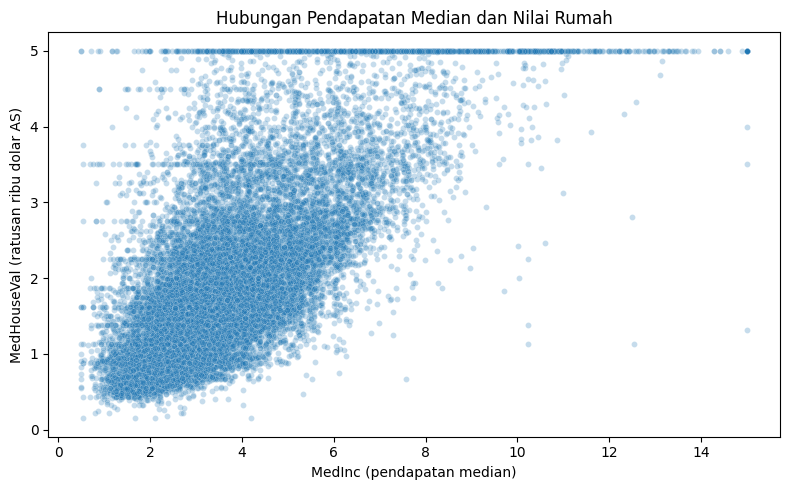

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y=target_column,
    alpha=0.25,
    s=18
)

plt.title("Hubungan Pendapatan Median dan Nilai Rumah")
plt.xlabel("MedInc (pendapatan median)")
plt.ylabel("MedHouseVal (ratusan ribu dolar AS)")
plt.tight_layout()
plt.show()

**Temuan:**

Scatter plot memperlihatkan kecenderungan hubungan positif antara `MedInc` dan `MedHouseVal`. Secara umum, wilayah dengan pendapatan median lebih tinggi cenderung memiliki nilai median rumah yang lebih tinggi pula. Meskipun begitu, titik-titik tidak membentuk garis yang sempurna, sehingga pendapatan median bukan satu-satunya faktor yang berkaitan dengan nilai rumah.

Terdapat pula penumpukan titik pada batas atas nilai target. Hal ini perlu diwaspadai karena dapat memengaruhi interpretasi hubungan antara fitur dan target.

## A3. Preprocessing Data

Preprocessing dilakukan untuk memastikan dataset memiliki kualitas yang baik sebelum digunakan dalam pemodelan. Pemeriksaan meliputi nilai yang hilang (missing values), data duplikat, dan outlier pada fitur numerik. Hasil pemeriksaan digunakan untuk menentukan apakah diperlukan penanganan lebih lanjut.

In [ ]:
import pandas as pd

# Mengecek nilai yang hilang pada setiap kolom
print("Jumlah missing values per kolom:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Mengecek jumlah baris duplikat
jumlah_duplikat = df.duplicated().sum()
print("Jumlah baris duplikat:", jumlah_duplikat)

# Menampilkan ukuran dataset saat ini
print("Ukuran dataset:", df.shape)

Jumlah missing values per kolom:


,Missing Values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Jumlah baris duplikat: 0
Ukuran dataset: (20640, 9)


In [ ]:
# Memeriksa outlier menggunakan metode IQR
# Variabel target tidak disertakan dalam pemeriksaan ini
fitur_numerik = [
    col for col in df.select_dtypes(include="number").columns
    if col != target_column
]

hasil_outlier = []

for col in fitur_numerik:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    jumlah = (
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ).sum()

    hasil_outlier.append({
        "Fitur": col,
        "Batas Bawah": round(batas_bawah, 2),
        "Batas Atas": round(batas_atas, 2),
        "Jumlah Outlier": jumlah
    })

display(pd.DataFrame(hasil_outlier))

,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier
0,MedInc,-0.71,8.01,681
1,HouseAge,-10.50,65.50,0
2,AveRooms,2.02,8.47,511
3,AveBedrms,0.87,1.24,1424
4,Population,-620.00,3132.00,1196
5,AveOccup,1.15,4.56,711
6,Latitude,28.26,43.38,0
7,Longitude,-127.48,-112.33,0


### Interpretasi dan Keputusan Preprocessing

Berdasarkan hasil pemeriksaan, dataset California Housing memiliki 20.640 baris dan 9 kolom. Seluruh kolom tidak memiliki missing values dan tidak ditemukan baris duplikat, sehingga tidak diperlukan penanganan nilai kosong maupun penghapusan data duplikat.

Pemeriksaan outlier menggunakan metode Interquartile Range (IQR) menunjukkan adanya nilai ekstrem pada fitur `MedInc`, `AveRooms`, `AveBedrms`, `Population`, dan `AveOccup`. Jumlah kandidat outlier berbeda pada setiap fitur. Nilai-nilai tersebut tidak langsung dihapus karena belum tentu merupakan kesalahan data dan dapat merepresentasikan kondisi nyata suatu wilayah.

Semua fitur dan variabel target bertipe numerik, sehingga tidak perlu encoding untuk variabel kategorikal. Pada pemodelan awal memakai Linear Regression tanpa regularisasi, scaling juga tidak diterapkan karena tidak wajib untuk menghasilkan prediksi. Data dipertahankan dalam bentuk aslinya agar satuan setiap fitur tetap mudah diinterpretasikan.

Dengan demikian, dataset dapat dilanjutkan ke tahap pemilihan fitur. Keberadaan nilai ekstrem dan batas atas variabel target tetap perlu dipertimbangkan saat mengevaluasi kualitas model.


## A4. Pemilihan Fitur (Feature Selection)

Pemilihan fitur dilakukan untuk menentukan variabel input yang dipakai dalam model Linear Regression. Analisis dilakukan dengan melihat korelasi setiap fitur terhadap variabel target `MedHouseVal` serta memeriksa korelasi antarfitur untuk mengidentifikasi potensi multikolinearitas.

Fitur tidak langsung dihapus hanya karena korelasinya dengan target rendah. Keputusan mempertahankan atau menghapus fitur juga mempertimbangkan informasi yang dibawanya dan kemungkinan kontribusinya terhadap model.

In [ ]:
import numpy as np
import pandas as pd

# memisahkan fitur input dan variabel target
feature_columns = [
    col for col in df.columns
    if col != target_column
]

# menghitung korelasi setiap fitur dengan target
target_correlation = df[feature_columns].corrwith(
    df[target_column]
)

# mengurutkan berdasarkan kekuatan korelasi absolut
target_correlation = target_correlation.reindex(
    target_correlation.abs().sort_values(
        ascending=False
    ).index
)

correlation_result = pd.DataFrame({
    "Korelasi dengan Target": target_correlation,
    "Korelasi Absolut": target_correlation.abs()
})

display(correlation_result.round(3))

,Korelasi dengan Target,Korelasi Absolut
MedInc,0.688,0.688
AveRooms,0.152,0.152
Latitude,-0.144,0.144
HouseAge,0.106,0.106
AveBedrms,-0.047,0.047
Longitude,-0.046,0.046
Population,-0.025,0.025
AveOccup,-0.024,0.024


In [ ]:
# menghitung korelasi antarfitur input saja
feature_corr = df[feature_columns].corr()

# mengambil setiap pasangan fitur satu kali
upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

pairs.columns = ["Fitur 1", "Fitur 2", "Korelasi"]

# menampilkan pasangan dengan korelasi absolut minimal 0,80
strong_pairs = pairs[
    pairs["Korelasi"].abs() >= 0.80
].sort_values(
    by="Korelasi",
    key=lambda x: x.abs(),
    ascending=False
)

if strong_pairs.empty:
    print("Tidak ditemukan pasangan fitur dengan korelasi absolut >= 0,80.")
else:
    print("Pasangan fitur dengan korelasi absolut >= 0,80:")
    display(strong_pairs.round(3))

Pasangan fitur dengan korelasi absolut >= 0,80:


,Fitur 1,Fitur 2,Korelasi
27,Latitude,Longitude,-0.925
13,AveRooms,AveBedrms,0.848


### Keputusan Pemilihan Fitur

Berdasarkan analisis korelasi terhadap variabel target `MedHouseVal`, fitur `MedInc` memiliki korelasi positif paling kuat sebesar 0,688. Fitur lainnya memiliki korelasi linear yang lebih lemah terhadap target.

Pemeriksaan multikolinearitas menunjukkan dua pasangan fitur dengan korelasi absolut minimal 0,80, yaitu `Latitude` dengan `Longitude` sebesar −0,925 serta `AveRooms` dengan `AveBedrms` sebesar 0,848.

Untuk model awal, fitur `AveBedrms` dihapus karena memiliki korelasi yang lebih lemah dengan target dibandingkan `AveRooms` dan berkorelasi tinggi dengan fitur tersebut. Sementara itu, `Latitude` dan `Longitude` tetap dipertahankan karena keduanya memberikan informasi koordinat geografis yang saling melengkapi.

Dengan demikian, terdapat tujuh fitur input yang dipertahankan, yaitu `MedInc`, `HouseAge`, `AveRooms`, `Population`, `AveOccup`, `Latitude`, dan `Longitude`. Variabel target yang digunakan adalah `MedHouseVal`.

Keputusan ini merupakan seleksi fitur awal berdasarkan korelasi dan pertimbangan karakteristik data. Pengaruh multikolinearitas serta kualitas prediksi tetap perlu dievaluasi setelah model dilatih.


In [ ]:
# menentukan fitur yang dipertahankan
selected_features = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude"
]

# memisahkan fitur input dan variabel target
X = df[selected_features].copy()
y = df[target_column].copy()

# menampilkan hasil pemilihan fitur
print("Fitur yang dipertahankan:", selected_features)
print("Jumlah fitur input:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("Variabel target:", target_column)
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Fitur yang dipertahankan: ['MedInc', 'HouseAge', 'AveRooms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Jumlah fitur input: 7
Jumlah data: 20640
Variabel target: MedHouseVal
Ukuran X: (20640, 7)
Ukuran y: (20640,)


## A5. Pembagian Data (Train-Test Split)

Dataset dibagi menjadi data latih dan data uji dengan rasio 80:20. Data latih digunakan untuk melatih model Linear Regression, sedangkan data uji digunakan untuk mengevaluasi kemampuan model dalam memprediksi data yang belum pernah dilihat selama pelatihan.

Pembagian data dilakukan menggunakan fungsi `train_test_split` dari scikit-learn dengan `random_state=42`. Penetapan nilai random state bertujuan agar hasil pembagian data dapat direproduksi ketika kode dijalankan kembali.

In [ ]:
from sklearn.model_selection import train_test_split

# membagi data dengan rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# menampilkan ukuran data setelah pembagian
print("Jumlah seluruh data:", len(X))
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

print("\nUkuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Jumlah seluruh data: 20640
Jumlah data latih: 16512
Jumlah data uji: 4128

Ukuran X_train: (16512, 7)
Ukuran X_test: (4128, 7)
Ukuran y_train: (16512,)
Ukuran y_test: (4128,)


### Interpretasi Pembagian Data

Dataset yang berjumlah 20.640 baris dibagi menjadi 16.512 data latih (80%) dan 4.128 data uji (20%). Data latih mempunyai tujuh fitur input dan digunakan untuk melatih model Linear Regression. Data uji mempunyai jumlah fitur yang sama dan disimpan untuk mengevaluasi performa model setelah pelatihan.

Parameter `random_state=42` digunakan agar pembagian data konsisten ketika kode dijalankan kembali dengan dataset dan konfigurasi yang sama.

## A6. Pemodelan (Linear Regression)

Model Linear Regression dipakai untuk memprediksi nilai median rumah (`MedHouseVal`) berdasarkan tujuh fitur input yang telah dipilih pada tahap A4.

Model dilatih memakai data latih (`X_train` dan `y_train`). Setelah pelatihan, koefisien setiap fitur dan intercept ditampilkan untuk memahami hubungan linear yang dipelajari model.

In [ ]:
from sklearn.linear_model import LinearRegression
import pandas as pd

# membuat dan melatih model Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# menampilkan koefisien setiap fitur
coefficient_df = pd.DataFrame({
    "Fitur": X_train.columns,
    "Koefisien": model.coef_
})

print("Koefisien setiap fitur:")
display(coefficient_df.round(4))

# menampilkan intercept
print("Intercept:", round(model.intercept_, 4))

Koefisien setiap fitur:


,Fitur,Koefisien
0,MedInc,0.3719
1,HouseAge,0.0098
2,AveRooms,0.0191
3,Population,-0.0000
4,AveOccup,-0.0032
5,Latitude,-0.4579
6,Longitude,-0.4646


Intercept: -38.9759


### Interpretasi Koefisien dan Intercept

Koefisien Linear Regression menunjukkan perubahan prediksi `MedHouseVal` untuk setiap kenaikan satu unit pada suatu fitur, dengan asumsi fitur lainnya tetap.

Koefisien positif menunjukkan hubungan linear searah dengan prediksi target, sedangkan koefisien negatif menunjukkan hubungan berlawanan arah. Besarnya koefisien perlu ditafsirkan berdasarkan satuan masing-masing fitur.

Intercept merupakan nilai prediksi model ketika semua fitur input bernilai nol. Nilai ini merupakan bagian dari persamaan model, tetapi belum tentu memiliki makna praktis untuk kondisi wilayah yang nyata.

Koefisien menggambarkan hubungan yang dipelajari model, bukan bukti hubungan sebab-akibat. Interpretasinya juga perlu mempertimbangkan korelasi antarf fitur yang telah ditemukan pada tahap A4.

## A7. Evaluasi Model

Evaluasi dilakukan untuk mengukur performa model Linear Regression pada data latih dan data uji. Metrik yang digunakan adalah Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), dan R-squared (R²).

Selain metrik evaluasi, dibuat visualisasi nilai aktual terhadap nilai prediksi dan residual plot untuk mengamati seberapa dekat prediksi dengan nilai sebenarnya serta pola kesalahan model.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# menghasilkan prediksi untuk data latih dan data uji
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# fungsi untuk menghitung metrik evaluasi
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R-squared": r2_score(y_true, y_pred)
    }

# menghitung metrik pada data latih dan data uji
train_metrics = calculate_metrics(y_train, y_train_pred)
test_metrics = calculate_metrics(y_test, y_test_pred)

# membandingkan hasil evaluasi
metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Data Latih", "Data Uji"]
)

display(metrics_df.round(4))

,MAE,MSE,RMSE,R-squared
Data Latih,0.5426,0.5353,0.7317,0.5995
Data Uji,0.5425,0.5473,0.7398,0.5823


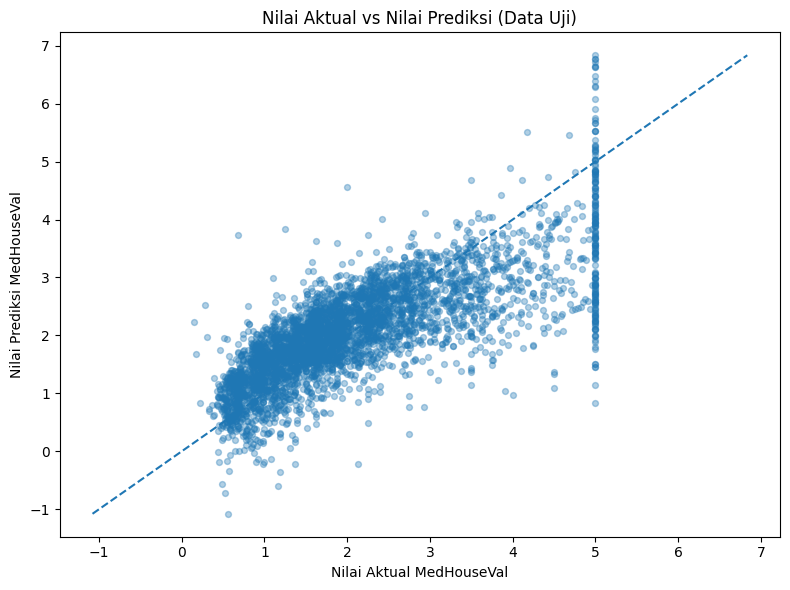

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.35,
    s=18
)

# garis prediksi ideal: nilai prediksi = nilai aktual
nilai_min = min(y_test.min(), y_test_pred.min())
nilai_max = max(y_test.max(), y_test_pred.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.title("Nilai Aktual vs Nilai Prediksi (Data Uji)")
plt.xlabel("Nilai Aktual MedHouseVal")
plt.ylabel("Nilai Prediksi MedHouseVal")
plt.tight_layout()
plt.show()

### Visualisasi 1 — Nilai Aktual vs Nilai Prediksi

Grafik ini membandingkan nilai aktual dan nilai prediksi `MedHouseVal` pada data uji. Garis diagonal menunjukkan kondisi prediksi ideal, yaitu ketika nilai prediksi sama dengan nilai aktual.

Titik-titik yang berada dekat dengan garis diagonal menunjukkan prediksi yang lebih akurat, sedangkan titik yang jauh dari garis menunjukkan kesalahan prediksi yang lebih besar. Pola penyebaran titik digunakan untuk menilai seberapa baik model mengikuti nilai aktual.

In [ ]:
# menghitung residual pada data uji
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.35,
    s=18
)

# garis residual nol
plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot (Data Uji)")
plt.xlabel("Nilai Prediksi MedHouseVal")
plt.ylabel("Residual (Aktual - Prediksi)")
plt.tight_layout()
plt.show()

### Visualisasi 2 — Residual Plot

Residual plot dipakai untuk melihat pola kesalahan prediksi model. Sumbu horizontal menunjukkan nilai prediksi, sedangkan sumbu vertikal menunjukkan residual, yaitu selisih antara nilai aktual dan nilai prediksi.

Residual yang tersebar relatif acak di sekitar garis nol merupakan salah satu indikasi bahwa model telah menangkap pola linear dengan cukup baik. Sebaliknya, pola melengkung, penyebaran yang semakin lebar, atau pengelompokan tertentu bisa mengindikasikan bahwa model belum menangkap seluruh pola data dengan baik.

### Interpretasi Hasil Evaluasi

Berdasarkan hasil evaluasi, nilai MAE, MSE, RMSE, dan R² pada data latih dibandingkan dengan data uji untuk menilai kualitas prediksi dan kemampuan generalisasi model.

Pada grafik aktual vs prediksi, kedekatan titik terhadap garis diagonal menunjukkan tingkat kesesuaian prediksi dengan nilai aktual. Pada residual plot, pola penyebaran residual di sekitar garis nol digunakan untuk menilai apakah masih terdapat pola kesalahan tertentu.

Perbedaan metrik antara data latih dan data uji digunakan untuk mengevaluasi kemungkinan overfitting atau underfitting. Kesimpulan akhir dibuat berdasarkan nilai metrik dan pola grafik yang benar-benar dihasilkan.

## A8. Analisis Performa Model

Analisis performa dilakukan untuk menilai kemampuan model Linear Regression dalam memprediksi nilai median rumah (`MedHouseVal`). Analisis mencakup perbandingan metrik data latih dan data uji untuk mengidentifikasi indikasi overfitting atau underfitting, pemeriksaan fitur yang paling berpengaruh terhadap prediksi, dan pembahasan keterbatasan model.

In [ ]:
# membandingkan metrik evaluasi data latih dan data uji
comparison_df = pd.DataFrame({
    "Data Latih": train_metrics,
    "Data Uji": test_metrics
})

comparison_df["Selisih (Uji - Latih)"] = (
    comparison_df["Data Uji"] - comparison_df["Data Latih"]
)

print("Perbandingan performa model:")
display(comparison_df.round(4))

# menampilkan selisih R-squared
r2_gap = train_metrics["R-squared"] - test_metrics["R-squared"]

print(f"Selisih R-squared (latih - uji): {r2_gap:.4f}")

In [ ]:
from sklearn.inspection import permutation_importance

# mengukur pengaruh setiap fitur terhadap MAE pada data uji
permutation_result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# membuat tabel importance
importance_df = pd.DataFrame({
    "Fitur": X_test.columns,
    "Rata-rata Importance": permutation_result.importances_mean,
    "Simpangan Baku": permutation_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Rata-rata Importance",
    ascending=False
).reset_index(drop=True)

print("Permutation Importance pada Data Uji:")
display(importance_df.round(4))

# menampilkan fitur dengan importance tertinggi
fitur_terpenting = importance_df.iloc[0]["Fitur"]
nilai_importance = importance_df.iloc[0]["Rata-rata Importance"]

print("Fitur dengan importance tertinggi:", fitur_terpenting)
print("Rata-rata importance:", round(nilai_importance, 4))

### Keterbatasan Model

Model Linear Regression memiliki beberapa keterbatasan. Pertama, model mengasumsikan hubungan linear antara fitur input dan variabel target, sehingga pola yang nonlinier atau interaksi kompleks antarf fitur belum tentu dapat ditangkap dengan baik.

Kedua, pemeriksaan A4 menunjukkan korelasi tinggi antara `Latitude` dan `Longitude`. Meskipun kedua fitur dipertahankan karena memberikan informasi lokasi, multikolinearitas dapat memengaruhi kestabilan interpretasi koefisien.

Ketiga, dataset memiliki nilai ekstrem pada beberapa fitur yang teridentifikasi menggunakan metode IQR. Nilai tersebut dipertahankan karena tidak terbukti sebagai kesalahan data, tetapi tetap dapat memengaruhi hasil pemodelan.

Keempat, distribusi target memiliki batas atas, sehingga prediksi untuk wilayah dengan nilai rumah tinggi dapat menjadi terbatas. Selain itu, dataset merepresentasikan kelompok wilayah sensus, bukan harga setiap rumah secara individual.

Terakhir, hasil evaluasi bergantung pada pembagian data dan karakteristik dataset California Housing yang digunakan. Model perlu diuji lebih lanjut sebelum digunakan pada wilayah atau data yang berbeda.